# 45 · Reward design: a shaping term that backfires, and potential-based shaping that doesn't

In [1]:
import numpy as np, gymnasium as gym, matplotlib.pyplot as plt

GOAL = 15

def manhattan(s):
    r, c = divmod(s, 4)
    return abs(r - 3) + abs(c - 3)

def q_learning(env, reward_fn, episodes=20000, alpha=0.1, gamma=0.99, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((16, 4))
    eps, true_returns, lengths = 1.0, [], []
    for ep in range(episodes):
        s, _ = env.reset(seed=seed * 10 ** 6 + ep); done, G, L = False, 0.0, 0
        while not done:
            a = int(rng.integers(4)) if rng.random() < eps else int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))
            s2, r, te, tr, _ = env.step(a)
            r_train = reward_fn(s, s2, r, te, gamma)
            Q[s, a] += alpha * (r_train + gamma * Q[s2].max() * (not te) - Q[s, a])
            s, done, G, L = s2, te or tr, G + r, L + 1
        true_returns.append(G); lengths.append(L); eps = max(0.05, eps * 0.999)
    return Q, np.array(true_returns), np.array(lengths)

def env_reward(s, s2, r, te, gamma):
    return r

def naive_shaping(s, s2, r, te, gamma):
    return r - 0.1 * manhattan(s2)

def hover_bonus(s, s2, r, te, gamma):
    return r + 0.1 * (manhattan(s2) <= 1)

def potential_shaping(s, s2, r, te, gamma):
    phi = lambda x: -0.1 * manhattan(x)
    return r + gamma * phi(s2) * (not te) - phi(s)

def greedy_eval(env, Q, n=500):
    wins, lengths = 0, []
    for i in range(n):
        s, _ = env.reset(seed=10 ** 7 + i); done, L = False, 0
        while not done:
            s, r, te, tr, _ = env.step(int(Q[s].argmax())); done, L = te or tr, L + 1
        wins += r; lengths.append(L)
    return wins / n, np.mean(lengths)

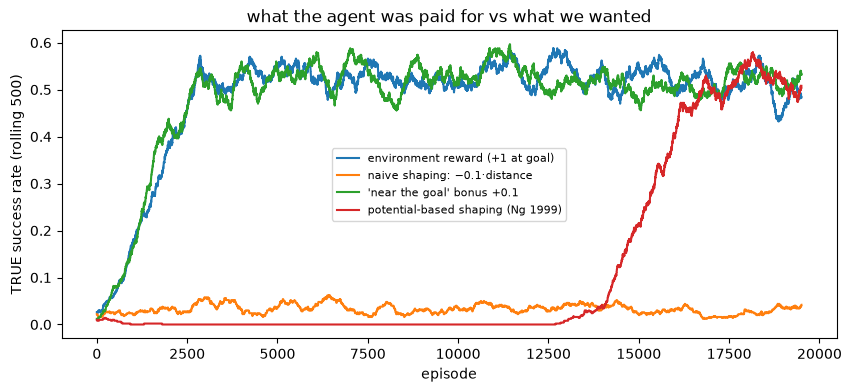

environment reward (+1 at goal)        greedy success 0.74   mean episode length  44.4
naive shaping: −0.1·distance           greedy success 0.04   mean episode length   4.7
'near the goal' bonus +0.1             greedy success 0.75   mean episode length  44.1
potential-based shaping (Ng 1999)      greedy success 0.72   mean episode length  41.3

naive shaping: falling into a hole ENDS the stream of distance penalties -> the agent learns to die quickly.
potential-based shaping keeps the optimal policy (same final success) but changes learning speed.


In [2]:
env = gym.make("FrozenLake-v1", is_slippery=True, max_episode_steps=100)
variants = {"environment reward (+1 at goal)": env_reward, "naive shaping: −0.1·distance": naive_shaping,
            "'near the goal' bonus +0.1": hover_bonus, "potential-based shaping (Ng 1999)": potential_shaping}
plt.figure(figsize=(10, 4))
table = {}
for name, fn in variants.items():
    Q, R, L = q_learning(env, fn)
    table[name] = greedy_eval(env, Q)
    plt.plot(np.convolve(R, np.ones(500) / 500, "valid"), label=name)
plt.ylabel("TRUE success rate (rolling 500)"); plt.xlabel("episode"); plt.legend(fontsize=8); plt.title("what the agent was paid for vs what we wanted"); plt.show()
for name, (sr, L) in table.items():
    print(f"{name:38s} greedy success {sr:.2f}   mean episode length {L:5.1f}")
print()
print("naive shaping: falling into a hole ENDS the stream of distance penalties -> the agent learns to die quickly.")
print("potential-based shaping keeps the optimal policy (same final success) but changes learning speed.")

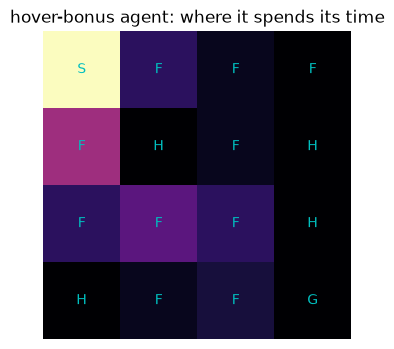

In [3]:
Q, _, _ = q_learning(env, hover_bonus)
s, _ = env.reset(seed=3); visits = np.zeros(16)
for _ in range(100):
    visits[s] += 1
    s, r, te, tr, _ = env.step(int(Q[s].argmax()))
    if te or tr:
        break
plt.figure(figsize=(4, 4)); plt.imshow(visits.reshape(4, 4), cmap="magma")
for k in range(16):
    plt.text(k % 4, k // 4, env.unwrapped.desc.astype(str).reshape(-1)[k], ha="center", va="center", color="c")
plt.title("hover-bonus agent: where it spends its time"); plt.axis("off"); plt.show()